# Bloodline · Validación de la simulación

Este notebook valida el motor del juego **Bloodline**. No reimplementa nada: importa el mismo paquete `bloodline` que usa la app, así que lo que se valida es exactamente lo que se juega.

**Qué se simula.** Cada persona tiene, para cada gen, 0, 1 o 2 copias del alelo recesivo (AA, Aa, aa). Para las enfermedades, el alelo recesivo es el de la enfermedad: 0 = sin copias, 1 = portador sano, 2 = enfermo.

**Por qué la distribución Multinomial.**
1. Un fundador tomado de una población en equilibrio de Hardy-Weinberg tiene genotipo ~ Multinomial(1; p², 2pq, q²).
2. El genotipo de un hijo dados sus padres también es Multinomial: cada padre pasa una de sus dos copias al azar (una moneda justa si es heterocigota). La probabilidad de cada genotipo sale del producto exterior de los vectores de "gametos" de ambos padres (el cuadro de Punnett).
3. Propagando esas matrices generación por generación se obtiene la probabilidad **exacta** del descendiente final. Eso permite comparar la simulación contra un valor teórico exacto.

**Plan de validación**
1. Fundadores vs Hardy-Weinberg (chi-cuadrado y momentos).
2. Cruza Aa × Aa vs proporciones de Mendel 1:2:1.
3. Árbol completo del juego: Monte Carlo vs probabilidad exacta.
4. Calibración: QQ-plot de p-valores contra la Uniforme(0, 1).
5. ¿Detectamos problemas? Un modelo "trucado" y la potencia del test.
6. Reproducibilidad con semilla.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from bloodline.config import load_config
from bloodline.game import Game, slot_sex
from bloodline.genetics import MendelianModel, hardy_weinberg, offspring_distribution, transmission_matrix
from bloodline.genetics.mendelian import one_hot

SEED = 2026
rng = np.random.default_rng(SEED)
cfg = load_config(ROOT / "data" / "config.json")
model = MendelianModel(cfg)

OBS, EXP, ACCENT = "#8c2f39", "#c9b79c", "#2f6a4e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GENOTYPES = ["AA (sin copias)", "Aa (portador)", "aa (enfermo)"]

pd.DataFrame(
    [(g.id, g.kind, g.label("es"), g.recessive_freq) for g in cfg.genes],
    columns=["gen", "tipo", "nombre", "q (frec. alelo recesivo)"],
)

,gen,tipo,nombre,q (frec. alelo recesivo)
0,d1,disease,Enfermedad 1,0.70
1,d2,disease,Enfermedad 2,0.15
2,d3,disease,Enfermedad 3,0.10
3,eyes,cosmetic,Color de ojos,0.45
4,hair,cosmetic,Color de pelo,0.35
5,freckles,cosmetic,Pecas,0.75


In [2]:
print("Matriz de transmisión T[k, alelo] (filas: 0, 1 o 2 copias; columnas: pasa A, pasa a)")
print(transmission_matrix())
print("\nEjemplo Aa x Aa -> P(AA, Aa, aa) =", offspring_distribution(one_hot(1), one_hot(1)))

Matriz de transmisión T[k, alelo] (filas: 0, 1 o 2 copias; columnas: pasa A, pasa a)
[[1.  0. ]
 [0.5 0.5]
 [0.  1. ]]

Ejemplo Aa x Aa -> P(AA, Aa, aa) = [0.25 0.5  0.25]


## 1. Fundadores bajo Hardy-Weinberg

Se generan N fundadores con el mismo `model.random_genome` que usa el juego y, para cada gen, se compara la frecuencia observada de cada genotipo con p², 2pq, q². Además se comparan los **momentos** del número de copias recesivas: bajo HW es Binomial(2, q), con media 2q y varianza 2pq.

In [3]:
N = 20_000
founders = [model.random_genome(rng) for _ in range(N)]

rows = []
for g in cfg.genes:
    x = np.array([f[g.id] for f in founders])
    obs = np.bincount(x, minlength=3)
    exp = N * hardy_weinberg(g.recessive_freq)
    chi = stats.chisquare(obs, exp)
    q = g.recessive_freq
    rows.append({
        "gen": g.id, "q": q,
        "obs AA/Aa/aa": "/".join(map(str, obs)),
        "esp AA/Aa/aa": "/".join(f"{e:.0f}" for e in exp),
        "chi2": round(chi.statistic, 2), "p-valor": round(chi.pvalue, 3),
        "media obs": round(x.mean(), 4), "media teórica 2q": round(2 * q, 4),
        "var obs": round(x.var(ddof=1), 4), "var teórica 2pq": round(2 * q * (1 - q), 4),
    })
hw_table = pd.DataFrame(rows)
hw_table

,gen,q,obs AA/Aa/aa,esp AA/Aa/aa,chi2,p-valor,media obs,media teórica 2q,var obs,var teórica 2pq
0,d1,0.70,1796/8459/9745,1800/8400/9800,0.73,0.694,1.3974,1.4,0.4191,0.420
1,d2,0.15,14564/5001/435,14450/5100/450,3.32,0.190,0.2936,0.3,0.2509,0.255
2,d3,0.10,16118/3670/212,16200/3600/200,2.50,0.287,0.2047,0.2,0.1840,0.180
3,eyes,0.45,6082/9836/4082,6050/9900/4050,0.84,0.658,0.9000,0.9,0.4982,0.495
4,hair,0.35,8560/9062/2378,8450/9100/2450,3.71,0.157,0.6909,0.7,0.4514,0.455
5,freckles,0.75,1303/7456/11241,1250/7500/11250,2.51,0.285,1.4969,1.5,0.3803,0.375


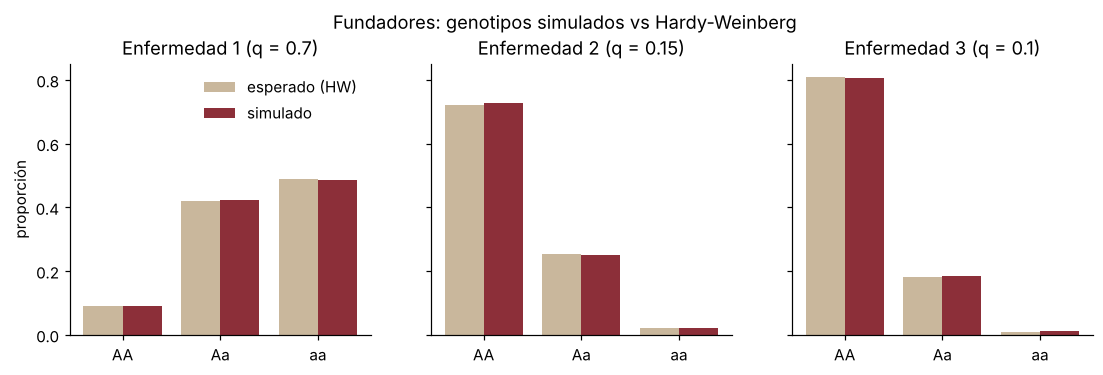

In [4]:
fig, axes = plt.subplots(1, len(cfg.diseases), figsize=(4 * len(cfg.diseases), 3.2), sharey=True)
for ax, g in zip(axes, cfg.diseases):
    x = np.array([f[g.id] for f in founders])
    obs = np.bincount(x, minlength=3) / N
    exp = hardy_weinberg(g.recessive_freq)
    pos = np.arange(3)
    ax.bar(pos - 0.2, exp, 0.4, color=EXP, label="esperado (HW)")
    ax.bar(pos + 0.2, obs, 0.4, color=OBS, label="simulado")
    ax.set_xticks(pos, ["AA", "Aa", "aa"])
    ax.set_title(f"{g.label('es')} (q = {g.recessive_freq})")
axes[0].set_ylabel("proporción")
axes[0].legend(frameon=False)
fig.suptitle("Fundadores: genotipos simulados vs Hardy-Weinberg", y=1.03)
plt.show()

**Lectura.** Todos los p-valores son altos (no hay evidencia contra HW) y la media y la varianza simuladas coinciden con 2q y 2pq hasta el tercer decimal.

## 2. Cruza Aa × Aa: proporciones de Mendel

Dos portadores tienen hijos AA, Aa y aa con probabilidades 1/4, 1/2 y 1/4. Se simulan 10.000 hijos con `model.child_genome`.

In [5]:
gid = cfg.diseases[0].id
carrier = {g.id: 1 for g in cfg.genes}
kids = np.array([model.child_genome(carrier, carrier, rng)[gid] for _ in range(10_000)])
obs = np.bincount(kids, minlength=3)
chi = stats.chisquare(obs, 10_000 * np.array([0.25, 0.5, 0.25]))
print("observado:", obs, " esperado: [2500 5000 2500]")
print(f"chi2 = {chi.statistic:.2f}, p-valor = {chi.pvalue:.3f}")

observado: [2472 5016 2512]  esperado: [2500 5000 2500]
chi2 = 0.42, p-valor = 0.810


## 3. El árbol completo del juego: Monte Carlo vs exacto

Se toma una partida real (semilla fija), se arma un árbol con 8 bisabuelos y se repite el nacimiento 20.000 veces (bisabuelos → abuelos → padres → yo) con las mismas funciones del juego. Se compara:
* la distribución de genotipos del descendiente para cada enfermedad, contra `pedigree_distributions`;
* la proporción de **victoria perfecta / victoria / derrota**, contra el `RiskReport` que muestra el juego al final.

In [6]:
game = Game(cfg, seed=4821)
for i in range(len(game.slots)):
    game.assign(i, game.candidates_of(slot_sex(i))[i // 2].id)
tree = [p.genome for p in game.founders()]
report = game.risk()

def simulate_descendant(founders, rng, model=model):
    level = founders
    while len(level) > 1:
        level = [model.child_genome(level[2 * i + 1], level[2 * i], rng) for i in range(len(level) // 2)]
    return level[0]

M = 20_000
sims = [simulate_descendant(tree, rng) for _ in range(M)]

pd.DataFrame(
    [{"bisabuelo": p.name, **{d.id: p.genome[d.id] for d in cfg.diseases}} for p in game.founders()]
).set_index("bisabuelo").T

bisabuelo,Gumersindo Villalba,Genoveva Molina,Venancio Sosa,Celestina Godoy,Jacinto Godoy,Remedios Cabrera,Abelardo Herrera,Dorotea Benítez
d1,2,2,2,2,1,0,2,1
d2,0,1,0,0,2,1,0,0
d3,0,0,0,0,0,1,0,0


In [7]:
rows = []
for d in cfg.diseases:
    exact = model.descendant_distribution(tree, d.id)
    obs = np.bincount([s[d.id] for s in sims], minlength=3)
    mask = exact > 0
    chi = stats.chisquare(obs[mask], M * exact[mask]) if mask.sum() > 1 else None
    rows.append({
        "enfermedad": d.label("es"),
        "exacto AA/Aa/aa": " / ".join(f"{e:.4f}" for e in exact),
        "simulado AA/Aa/aa": " / ".join(f"{o / M:.4f}" for o in obs),
        "chi2": None if chi is None else round(chi.statistic, 2),
        "p-valor": None if chi is None else round(chi.pvalue, 3),
    })
pd.DataFrame(rows)

,enfermedad,exacto AA/Aa/aa,simulado AA/Aa/aa,chi2,p-valor
0,Enfermedad 1,0.0000 / 0.5000 / 0.5000,0.0000 / 0.4995 / 0.5004,0.02,0.899
1,Enfermedad 2,0.5469 / 0.4062 / 0.0469,0.5464 / 0.4058 / 0.0478,0.38,0.826
2,Enfermedad 3,0.8750 / 0.1250 / 0.0000,0.8732 / 0.1268 / 0.0000,0.56,0.454


In [8]:
def outcome(genome):
    ph = model.phenotype(genome)
    return "derrota" if ph.affected else "victoria" if ph.carrier else "perfecta"

labels = ["perfecta", "victoria", "derrota"]
expected = np.array([report.p_perfect, report.p_win_carrier, report.p_loss])
counts = pd.Series([outcome(s) for s in sims]).value_counts().reindex(labels, fill_value=0).to_numpy()
possible = expected > 0  # outcomes with probability 0 must never appear and are left out of the test
assert counts[~possible].sum() == 0
chi = stats.chisquare(counts[possible], M * expected[possible])
print("exacto  :", {k: round(float(v), 4) for k, v in zip(labels, expected)})
print("simulado:", {k: round(float(v), 4) for k, v in zip(labels, counts / M)})
print(f"chi2 = {chi.statistic:.2f}, p-valor = {chi.pvalue:.3f}")

exacto  : {'perfecta': 0.0, 'victoria': 0.4766, 'derrota': 0.5234}
simulado: {'perfecta': 0.0, 'victoria': 0.4752, 'derrota': 0.5249}
chi2 = 0.16, p-valor = 0.689


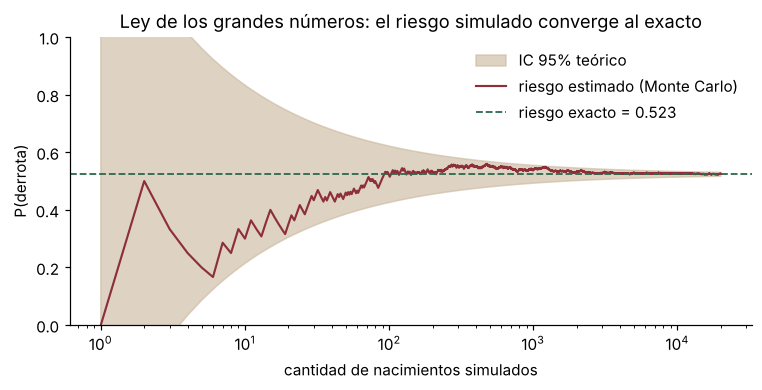

In [9]:
losses = np.array([outcome(s) == "derrota" for s in sims])
n = np.arange(1, M + 1)
running = losses.cumsum() / n
band = 1.96 * np.sqrt(report.p_loss * (1 - report.p_loss) / n)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.fill_between(n, report.p_loss - band, report.p_loss + band, color=EXP, alpha=0.6, label="IC 95% teórico")
ax.plot(n, running, color=OBS, lw=1.4, label="riesgo estimado (Monte Carlo)")
ax.axhline(report.p_loss, color=ACCENT, ls="--", lw=1.2, label=f"riesgo exacto = {report.p_loss:.3f}")
ax.set_xscale("log"); ax.set_xlabel("cantidad de nacimientos simulados"); ax.set_ylabel("P(derrota)")
ax.set_ylim(0, min(1, 3 * report.p_loss + 0.05)); ax.legend(frameon=False, loc="upper right")
ax.set_title("Ley de los grandes números: el riesgo simulado converge al exacto")
plt.show()

## 4. Calibración: QQ-plot de p-valores

Si la simulación es correcta, al repetir el test chi-cuadrado sobre muchas muestras independientes los p-valores deben seguir una **Uniforme(0, 1)**. Se generan 1.000 muestras de 400 fundadores, se testea HW en cada una y se grafica el QQ-plot de los p-valores contra la Uniforme. Se complementa con un test de Kolmogorov-Smirnov.

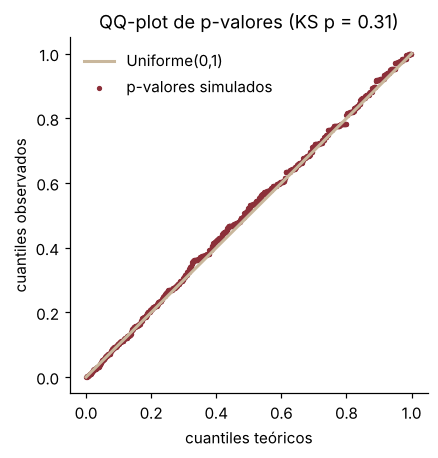

Proporción de rechazos al 5%: 0.049 (esperado ≈ 0.05)


In [10]:
g = cfg.diseases[0]
exp = hardy_weinberg(g.recessive_freq)
pvals = []
for _ in range(1_000):
    x = np.array([model.random_genome(rng)[g.id] for _ in range(400)])
    pvals.append(stats.chisquare(np.bincount(x, minlength=3), 400 * exp).pvalue)
pvals = np.sort(pvals)
theo = (np.arange(1, len(pvals) + 1) - 0.5) / len(pvals)
ks = stats.kstest(pvals, "uniform")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot([0, 1], [0, 1], color=EXP, lw=2, label="Uniforme(0,1)")
ax.scatter(theo, pvals, s=6, color=OBS, label="p-valores simulados")
ax.set_xlabel("cuantiles teóricos"); ax.set_ylabel("cuantiles observados")
ax.set_title(f"QQ-plot de p-valores (KS p = {ks.pvalue:.2f})"); ax.legend(frameon=False)
plt.show()
print(f"Proporción de rechazos al 5%: {(pvals < 0.05).mean():.3f} (esperado ≈ 0.05)")

Los puntos siguen la diagonal (la escalera se debe a que el genotipo es discreto) y la tasa de rechazo al 5% es cercana a 0.05: el test está bien calibrado y la simulación no muestra sesgos.

## 5. ¿Detectamos problemas? Un modelo trucado

Para comprobar que la validación **sí detecta** errores, se simula un modelo con *distorsión de segregación*: los heterocigotos pasan el alelo recesivo con probabilidad `h` en lugar de 0.5. Se compara contra lo que predice Mendel (h = 0.5) en cruzas Aa × Aa.

In [11]:
biased = MendelianModel(cfg, het_transmission=0.6)
kids = np.array([biased.child_genome(carrier, carrier, rng)[gid] for _ in range(5_000)])
obs = np.bincount(kids, minlength=3)
chi = stats.chisquare(obs, 5_000 * np.array([0.25, 0.5, 0.25]))
print("h = 0.6 ->", obs / 5_000, f"chi2 = {chi.statistic:.1f}, p-valor = {chi.pvalue:.2e}  -> se rechaza Mendel")

h = 0.6 -> [0.1618 0.4792 0.359 ] chi2 = 397.5, p-valor = 4.76e-87  -> se rechaza Mendel


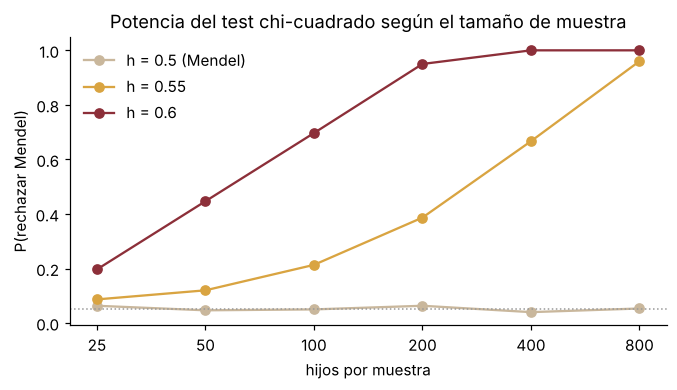

In [12]:
def power(h, n, reps=300):
    m = MendelianModel(cfg, het_transmission=h)
    rejected = 0
    for _ in range(reps):
        k = np.bincount([m.child_genome(carrier, carrier, rng)[gid] for _ in range(n)], minlength=3)
        rejected += stats.chisquare(k, n * np.array([0.25, 0.5, 0.25])).pvalue < 0.05
    return rejected / reps

sizes = [25, 50, 100, 200, 400, 800]
curves = {h: [power(h, n) for n in sizes] for h in (0.5, 0.55, 0.6)}

fig, ax = plt.subplots(figsize=(7, 3.4))
for (h, ys), color in zip(curves.items(), (EXP, "#d9a441", OBS)):
    ax.plot(sizes, ys, marker="o", color=color, label=f"h = {h}" + (" (Mendel)" if h == 0.5 else ""))
ax.axhline(0.05, color="#999", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xticks(sizes, sizes); ax.minorticks_off()
ax.set_xlabel("hijos por muestra"); ax.set_ylabel("P(rechazar Mendel)")
ax.set_title("Potencia del test chi-cuadrado según el tamaño de muestra"); ax.legend(frameon=False)
plt.show()

**Lectura.** Con el modelo correcto (h = 0.5) la tasa de rechazo se queda en ≈5%. Un sesgo grande (h = 0.6) se detecta casi siempre con unas pocas centenas de hijos, pero un sesgo chico (h = 0.55) con muestras chicas pasa desapercibido: **el test no tiene poder con pocos datos**. Por eso las validaciones de arriba usan decenas de miles de simulaciones.

## 6. Reproducibilidad

In [13]:
a, b, c = Game(cfg, seed=777), Game(cfg, seed=777), Game(cfg, seed=778)
same = [x.genome for x in a.candidates] == [x.genome for x in b.candidates]
diff = [x.genome for x in a.candidates] != [x.genome for x in c.candidates]
for gm in (a, b):
    for i in range(len(gm.slots)):
        gm.assign(i, gm.candidates_of(slot_sex(i))[i // 2].id)
print("misma semilla -> mismos candidatos:", same)
print("misma semilla y mismo árbol -> mismo descendiente:", a.resolve().me.genome == b.resolve().me.genome)
print("otra semilla -> otros candidatos:", diff)

misma semilla -> mismos candidatos: True
misma semilla y mismo árbol -> mismo descendiente: True
otra semilla -> otros candidatos: True


## 7. Limitaciones del modelo

* **Un gen por rasgo.** Cada enfermedad y cada rasgo visible depende de un único gen con dos alelos. En la realidad el color de ojos o de pelo depende de muchos genes; el color de piel se excluyó de la genética y se hereda de uno de los padres al azar.
* **Penetrancia completa.** Tener aa implica enfermarse siempre. Muchas enfermedades reales tienen penetrancia incompleta.
* **Genes independientes.** No hay ligamiento entre genes ni mutaciones nuevas.
* **Sin endogamia.** Los 8 bisabuelos son personas distintas y no emparentadas; el cálculo exacto supone que los dos padres de cada persona son independientes.
* **Frecuencias inventadas.** Las frecuencias alélicas se eligieron para que el juego sea desafiante (≈50% de riesgo con un árbol al azar y ≈40% leyendo las pistas), no para representar enfermedades reales.
* **Potencia limitada.** Como muestra la sección 5, desviaciones chicas del modelo solo se detectan con muestras grandes.